# Klasifikasi Teks: Analisis Sentimen Bahasa Indonesia

- **Nama:** `MUHAMMAD HAFIDZUL FIKRI`
- **NIM:** `25917043`
- **Repositori GitHub:** `https://github.com/25917043-bit/uts_analitik_teks/`


## Bagian 0: Identifikasi Masalah

### Isu Terkini
Perkembangan kecerdasan buatan (AI) memperparah penyebaran **ujaran kebencian, hoaks, dan kampanye negatif** di media sosial, khususnya menjelang penyelenggaraan Pemilu. Artikel *Kompas.com* berjudul **"Bawaslu Sebut Perkembangan AI Jadi Tantangan Pemilu 2029"** (27 Juli 2026) melaporkan bahwa pada pengawasan Pemilu/Pilkada 2024, **akun anonim mendominasi penyebaran ujaran kebencian dan hoaks**, serta AI mempermudah produksi teks, gambar, video, dan rekaman suara yang sulit diverifikasi keasliannya.

**Tautan artikel (dilampirkan):** <https://www.kompas.com/cekfakta/read/2026/07/27/084000282/bawaslu-sebut-perkembangan-ai-jadi-tantangan-pemilu-2029>

### Rancangan Solusi Klasifikasi Teks
Karena volume unggahan media sosial sangat besar dan mustahil ditinjau manual satu per satu, masalah ini tepat diselesaikan dengan **klasifikasi teks**. Solusi yang dirancang adalah sistem yang mempelajari pola dari teks berlabel untuk **mengelompokkan sebuah unggahan/kalimat ke kategori tertentu secara otomatis** — misalnya sentimen (positif/netral/negatif) atau ujaran kebencian (benci vs bukan benci).

Rancangan pipeline (diimplementasikan pada bagian-bagian selanjutnya):

1. **Pengumpulan data** berlabel (Bagian 1);
2. **Pra-pemrosesan teks** (Bagian 2);
3. **Ekstraksi fitur** TF-IDF dan Word2Vec (Bagian 3);
4. **Analisis eksploratif** (Bagian 4);
5. **Pelatihan & evaluasi** classifier Naive Bayes, SVM, dan Logistic Regression (Bagian 5).

> Pada notebook ini, tugas klasifikasi yang didemonstrasikan adalah **analisis sentimen** (positif/netral/negatif) menggunakan dataset NusaX-senti. Seluruh pipeline (pra-pemrosesan → fitur → klasifikasi) identik dan dapat langsung diterapkan pada **deteksi ujaran kebencian/hoaks** — yang berbeda hanya label dan datanya.


## Persiapan Lingkungan

Sel berikut memastikan semua pustaka yang dibutuhkan terpasang. Jika dijalankan di Google Colab, sel ini akan menginstal pustaka yang belum ada; jika sudah terpasang, sel ini tidak melakukan apa-apa.


In [ ]:
# Instalasi otomatis dependensi (aman dijalankan ulang; no-op bila sudah terpasang)
import importlib
import subprocess
import sys

def _pasang(modul, nama_pip):
    try:
        importlib.import_module(modul)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", nama_pip])

# (modul_import, nama_paket_pip)
dependensi = [
    ("pandas", "pandas"),
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
    ("seaborn", "seaborn"),
    ("sklearn", "scikit-learn"),
    ("nltk", "nltk"),
    ("gensim", "gensim"),
    ("Sastrawi", "Sastrawi"),
    ("wordcloud", "wordcloud"),
]

for m, p in dependensi:
    _pasang(m, p)

print("Semua dependensi siap.")


/Users/bsi-2-2200076/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Semua dependensi siap.


In [ ]:
# Impor pustaka utama
import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Gaya visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Impor selesai.")


Impor selesai.


In [ ]:
# Unduh data NLTK (tokenizer + stopwords) bila belum tersedia
import nltk
from nltk.tokenize import word_tokenize

for resource in ["punkt", "punkt_tab"]:
    try:
        nltk.data.find("tokenizers/" + resource)
    except LookupError:
        nltk.download(resource, quiet=True)

# Uji tokenisasi sederhana
print(word_tokenize("saya sangat senang dengan aplikasi ini"))


['saya', 'sangat', 'senang', 'dengan', 'aplikasi', 'ini']


## Bagian 1: Pengumpulan Data (Poin 10)

### 1.1 Penjelasan Dataset
Dataset yang digunakan adalah **NusaX-senti** (bagian dari benchmark multibahasa NusaX — Winata et al., 2022), khususnya subset **Bahasa Indonesia**. Dataset ini tersedia secara publik di Hugging Face: `indonlp/NusaX-senti`.

| Aspek | Keterangan |
|---|---|
| **Sumber** | Hugging Face `indonlp/NusaX-senti` (NusaX benchmark) |
| **Jumlah sampel** | 1.000 kalimat berbahasa Indonesia (gabungan split train/validation/test) |
| **Fitur** | `text` (kalimat), `label` (0/1/2), `label_name` (negatif/netral/positif) |
| **Label** | `0` = negatif, `1` = netral, `2` = positif |
| **Lisensi** | Terbuka untuk penelitian (NusaX — CC-BY-NC-SA 4.0) |

### 1.2 Kode Pengumpulan Data
Sel berikut memuat data dari **file CSV yang dilampirkan** (`data/nusax_senti_ind.csv`). Jika file belum ada (misalnya saat menjalankan di Colab), kode otomatis **mengunduh langsung file parquet NusaX-senti** dari Hugging Face sebagai cadangan.


In [ ]:
# --- Pengumpulan data ---
CSV_PATH = "data/nusax_senti_ind.csv"
NAMA_LABEL = {0: "negatif", 1: "netral", 2: "positif"}

if os.path.exists(CSV_PATH):
    # (1) Baca dataset yang dilampirkan
    df = pd.read_csv(CSV_PATH)
    print("Dataset dimuat dari file CSV terlampir.")
else:
    # (2) Cadangan: unduh parquet NusaX-senti (Bahasa Indonesia) dari Hugging Face
    print("CSV tidak ditemukan, mengunduh dari Hugging Face ...")
    base = ("https://huggingface.co/datasets/indonlp/NusaX-senti/"
            "resolve/refs%2Fconvert%2Fparquet/ind")
    frames = [
        pd.read_parquet(f"{base}/{split}/0000.parquet")[["text", "label"]]
        for split in ("train", "validation", "test")
    ]
    df = pd.concat(frames, ignore_index=True)
    df["label_name"] = df["label"].map(NAMA_LABEL)

print("Jumlah sampel:", len(df))
print("Kolom:", list(df.columns))


Dataset dimuat dari file CSV terlampir.
Jumlah sampel: 1000
Kolom: ['text', 'label', 'label_name']


In [ ]:
# Ringkasan dataset
print("=== 5 baris pertama ===")
display(df.head())

print("\n=== Distribusi label ===")
print(df["label_name"].value_counts())

print("\n=== Info dataframe ===")
df.info()


=== 5 baris pertama ===


,text,label,label_name
0,Nikmati cicilan 0% hingga 12 bulan untuk pemes...,1,netral
1,Kue-kue yang disajikan bikin saya bernostalgia...,2,positif
2,Ibu pernah bekerja di grab indonesia,1,netral
3,Paling suka banget makan siang di sini ayam sa...,2,positif
4,Pelayanan bus DAMRI sangat baik,2,positif



=== Distribusi label ===
label_name
negatif    383
positif    378
netral     239
Name: count, dtype: int64

=== Info dataframe ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   text        1000 non-null   object
 1   label       1000 non-null   int64 
 2   label_name  1000 non-null   object
dtypes: int64(1), object(2)
memory usage: 23.6+ KB


## Bagian 2: Pra-pemrosesan Teks (Poin 20)

Tahapan pra-pemrosesan yang dilakukan:

1. **Lowercasing** — seluruh teks diubah menjadi huruf kecil agar tidak ada kata yang terduplikasi hanya karena kapitalisasi.
2. **Penghapusan tanda baca & karakter khusus** — menghapus URL, mention (`@user`), hashtag (`#tag`), dan tanda baca menggunakan *regular expression*.
3. **Tokenisasi** — memecah teks menjadi daftar kata (token) dengan `nltk.word_tokenize`.
4. **Penghapusan stopwords** — membuang kata umum yang tidak bermakna (mis. "yang", "dan", "di") menggunakan daftar stopwords Bahasa Indonesia dari pustaka **Sastrawi**.
5. **Stemming** — mengembalikan kata ke bentuk dasarnya (mis. "menggunakan" → "guna") dengan **Sastrawi**.


In [ ]:
# --- Pra-pemrosesan teks ---
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Daftar stopwords Bahasa Indonesia dari Sastrawi
stopwords_id = set(StopWordRemoverFactory().get_stop_words())
# Stemmer Bahasa Indonesia dari Sastrawi
stemmer = StemmerFactory().create_stemmer()

def preprocess(teks, join=True):
    """Membersihkan satu teks Bahasa Indonesia.

    Parameter
    ----------
    teks : str
        Teks mentah.
    join : bool
        Jika True, kembalikan string bersih (untuk TF-IDF).
        Jika False, kembalikan list token (untuk Word2Vec).
    """
    # (d) Lowercasing
    teks = teks.lower()
    # (e) Hapus URL, mention, hashtag, lalu tanda baca & karakter khusus
    teks = re.sub(r"http\S+|www\.\S+", " ", teks)
    teks = re.sub(r"@\w+|#\w+", " ", teks)
    teks = re.sub(r"[^a-z0-9\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()
    # (a) Tokenisasi
    token = word_tokenize(teks)
    # (b) Hapus stopwords dan token sepanjang 1 karakter
    token = [t for t in token if t not in stopwords_id and len(t) > 1]
    # (c) Stemming
    token = [stemmer.stem(t) for t in token]
    return " ".join(token) if join else token

# Terapkan ke seluruh dataset (hasilnya dipakai di bagian-bagian selanjutnya)
df["clean_text"] = df["text"].apply(preprocess)          # string bersih (untuk TF-IDF)
df["tokens"] = df["text"].apply(lambda t: preprocess(t, join=False))  # list token (untuk Word2Vec)

print("Pra-pemrosesan selesai.")


Pra-pemrosesan selesai.


In [ ]:
# Contoh teks SEBELUM vs SESUDAH pra-pemrosesan
contoh = df[["text", "clean_text"]].head(6).rename(
    columns={"text": "SEBELUM (teks asli)", "clean_text": "SESUDAH (clean_text)"}
)
for i, (before, after) in enumerate(contoh.values, start=1):
    print(f"[{i}] SEBELUM : {before}")
    print(f"    SESUDAH : {after}")
    print()


[1] SEBELUM : Nikmati cicilan 0% hingga 12 bulan untuk pemesanan tiket pesawat air asia dengan kartu kredit bni!
    SESUDAH : nikmat cicil hingga 12 bulan mesan tiket pesawat air asia kartu kredit bni

[2] SEBELUM : Kue-kue yang disajikan bikin saya bernostalgia. Semuanya tipikal kue zaman dulu, baik dari penampilan maupun rasa. Kuenya enak dan harganya juga murah.
    SESUDAH : kue kue saji bikin nostalgia semua tipikal kue zaman dulu baik tampil maupun rasa kue enak harga murah

[3] SEBELUM : Ibu pernah bekerja di grab indonesia
    SESUDAH : ibu pernah kerja grab indonesia

[4] SEBELUM : Paling suka banget makan siang di sini ayam sama sambalnya enak banget harganya luar biasa hemat, rasa ayamnya meresap sampai ketulangnya, es lidah buayanya juga segar bikin adem perut setelah makan sambal yang pedas, pelayannya sigap dan ramah, yang aku suka di tempat kasir ada tulisan 10% disumbangkan untuk beramal, buat makan jadi lebih enak ke perut
    SESUDAH : paling suka banget makan siang 

## Bagian 3: Rekayasa Fitur (Poin 10)

Model machine learning tidak dapat memproses teks mentah secara langsung, sehingga teks harus diubah menjadi representasi numerik. Pada bagian ini diterapkan dua teknik ekstraksi fitur.

### 3.1 TF-IDF (Term Frequency–Inverse Document Frequency)
**Konsep:** TF-IDF memberi bobot pada setiap kata berdasarkan dua komponen:

- **TF (Term Frequency)** — seberapa sering kata muncul dalam sebuah dokumen.
- **IDF (Inverse Document Frequency)** — mengukur seberapa langka kata tersebut di seluruh korpus; kata yang muncul di hampir semua dokumen (mis. kata umum) diberi bobot kecil, sedangkan kata yang khas untuk sebagian dokumen diberi bobot besar.

Hasilnya adalah matriks `dokumen × kata` yang berisi bobot numerik untuk tiap kata pada tiap dokumen.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Buat representasi TF-IDF (unigram + bigram, maksimal 5000 fitur)
tfidf_vec = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_tfidf = tfidf_vec.fit_transform(df["clean_text"])

print("Bentuk matriks TF-IDF (dokumen x fitur):", X_tfidf.shape)
print("Contoh fitur (vocabulary):", list(tfidf_vec.get_feature_names_out())[:15])


Bentuk matriks TF-IDF (dokumen x fitur): (1000, 5000)
Contoh fitur (vocabulary): ['000', '000 orang', '10', '10 ribu', '100', '100 ribu', '12', '120', '120 ribu', '13', '14', '14000', '15', '15 000', '16']


In [ ]:
# Lihat bobot TF-IDF tertinggi pada satu dokumen contoh
dok_idx = 0
fitur = tfidf_vec.get_feature_names_out()
baris = X_tfidf[dok_idx].toarray().flatten()
top_idx = baris.argsort()[::-1][:10]

print("Dokumen:", df["clean_text"].iloc[dok_idx])
print("\nKata dengan bobot TF-IDF tertinggi:")
for i in top_idx:
    print(f"  {fitur[i]:15s} -> {baris[i]:.4f}")


Dokumen: nikmat cicil hingga 12 bulan mesan tiket pesawat air asia kartu kredit bni

Kata dengan bobot TF-IDF tertinggi:
  pesawat air     -> 0.2810
  mesan tiket     -> 0.2810
  nikmat cicil    -> 0.2810
  tiket pesawat   -> 0.2652
  cicil           -> 0.2652
  pesawat         -> 0.2540
  mesan           -> 0.2453
  kartu kredit    -> 0.2382
  kredit          -> 0.2322
  12              -> 0.2322


### 3.2 Word2Vec
**Konsep:** Word2Vec adalah model *word embedding* berbasis jaringan saraf yang memetakan setiap kata ke sebuah **vektor padat berdimensi rendah** (di sini 100 dimensi) sehingga kata-kata yang sering muncul dalam konteks serupa akan memiliki vektor yang berdekatan. Berbeda dengan TF-IDF yang menghasilkan representasi *sparse* per dokumen, Word2Vec menghasilkan representasi *dense* per kata yang menangkap makna semantik.

Model Word2Vec dilatih secara *unsupervised* pada token hasil pra-pemrosesan menggunakan arsitektur **skip-gram** (default di Gensim).


In [ ]:
from gensim.models import Word2Vec

# Siapkan korpus berupa daftar daftar-token
kalimat = df["tokens"].tolist()

# Latih Word2Vec (skip-gram, 100 dimensi, kata minimal muncul 2 kali)
w2v = Word2Vec(sentences=kalimat, vector_size=100, window=5,
               min_count=2, workers=4, seed=42, epochs=30)

print("Ukuran kosakata:", len(w2v.wv))
print("Dimensi vektor:", w2v.wv.vector_size)


Ukuran kosakata: 1456
Dimensi vektor: 100


In [ ]:
# Contoh vektor embedding sebuah kata
kata = "aplikasi"
if kata in w2v.wv:
    print(f"Vektor '{kata}' (10 komponen pertama):")
    print(w2v.wv[kata][:10].round(4))
else:
    print(f"Kata '{kata}' tidak ada di kosakata.")


Vektor 'aplikasi' (10 komponen pertama):
[ 0.143  -0.118  -0.3007  0.0248 -0.1622  0.255   0.2874  0.1153 -0.1434
  0.1212]


In [ ]:
# Kata-kata yang paling mirip secara semantik
for kata in ["aplikasi", "bagus", "buruk"]:
    if kata in w2v.wv:
        try:
            mirip = w2v.wv.most_similar(kata, topn=5)
            print(f"Kata terdekat '{kata}':", [f"{w} ({s:.2f})" for w, s in mirip])
        except KeyError:
            print(f"'{kata}': tidak cukup tetangga (korpus kecil).")
    else:
        print(f"Kata '{kata}' tidak ada di kosakata.")


Kata terdekat 'aplikasi': ['gojek (1.00)', 'bni (1.00)', 'kamu (1.00)', 'cek (1.00)', 'biar (1.00)']
Kata terdekat 'bagus': ['suasana (0.99)', 'sangat (0.98)', 'pandang (0.97)', 'luar (0.97)', 'nyaman (0.97)']
Kata terdekat 'buruk': ['channel (1.00)', 'rakyat (1.00)', 'men (1.00)', 'tonton (1.00)', 'malas (1.00)']


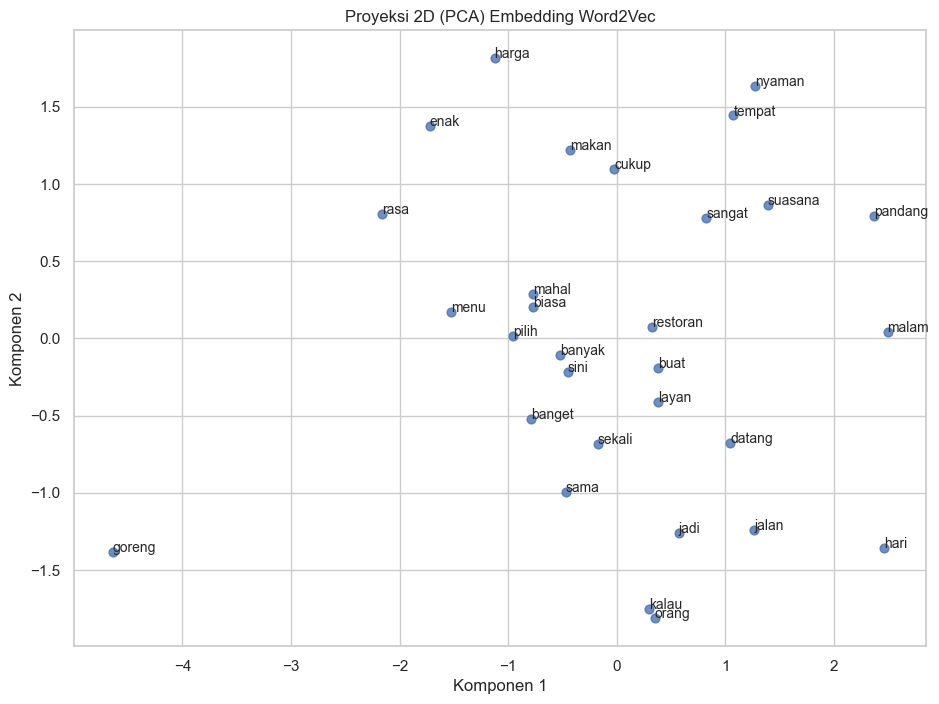

In [ ]:
# Visualisasi embedding Word2Vec dengan PCA (proyeksi 2D kata-kata paling sering)
from sklearn.decomposition import PCA

# Ambil 40 kata paling sering yang ada di kosakata Word2Vec
frekuensi = Counter([t for ts in df["tokens"] for t in ts])
kata_umum = [w for w, _ in frekuensi.most_common(40) if w in w2v.wv][:30]

vektor = np.array([w2v.wv[w] for w in kata_umum])
pca = PCA(n_components=2, random_state=42).fit_transform(vektor)

plt.figure(figsize=(11, 8))
plt.scatter(pca[:, 0], pca[:, 1], s=40, alpha=0.8)
for w, (x, y) in zip(kata_umum, pca):
    plt.annotate(w, (x, y), fontsize=10)
plt.title("Proyeksi 2D (PCA) Embedding Word2Vec")
plt.xlabel("Komponen 1")
plt.ylabel("Komponen 2")
plt.show()


## Bagian 4: Analisis Data Eksploratif dan Visualisasi (Poin 20)

Analisis eksploratif dilakukan untuk memahami karakteristik data sebelum pemodelan.


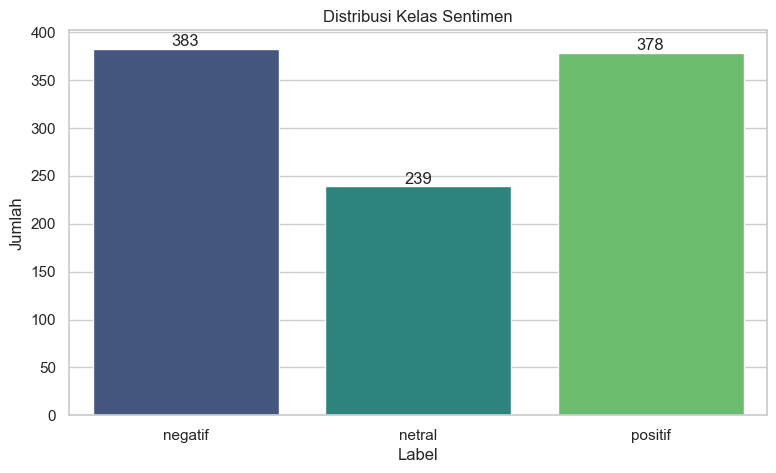

In [ ]:
# (a) Distribusi kelas label
urutan = ["negatif", "netral", "positif"]
ax = sns.countplot(data=df, x="label_name", order=urutan, palette="viridis")
ax.set_title("Distribusi Kelas Sentimen")
ax.set_xlabel("Label")
ax.set_ylabel("Jumlah")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.show()


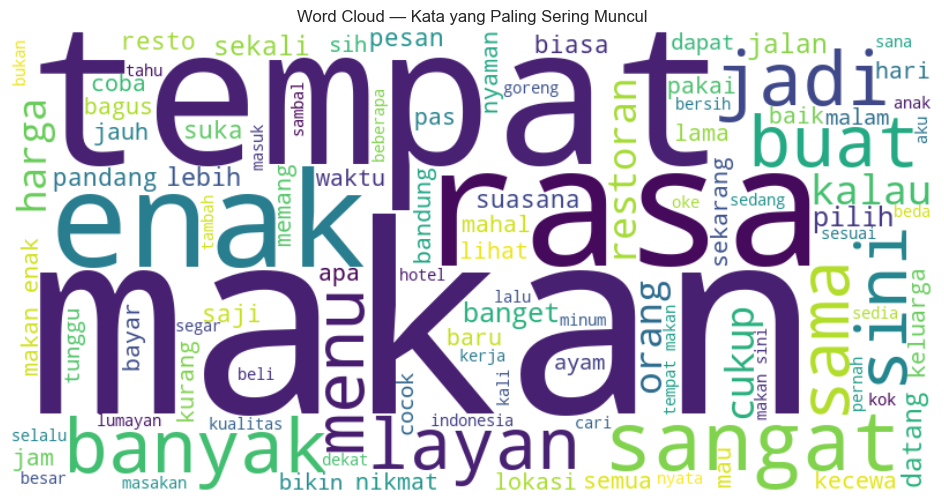

In [ ]:
# (a) Word cloud kata-kata yang paling sering muncul
from wordcloud import WordCloud

semua_teks = " ".join(df["clean_text"])
wordcloud = WordCloud(width=800, height=400, background_color="white",
                      max_words=100, colormap="viridis", random_state=42).generate(semua_teks)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — Kata yang Paling Sering Muncul")
plt.show()


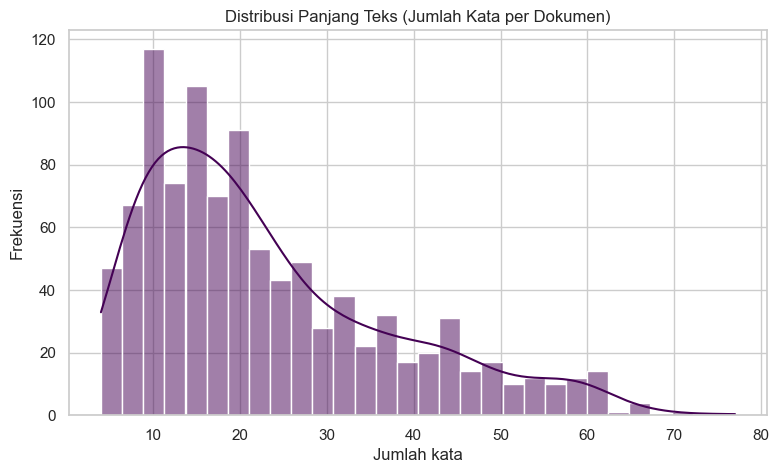

Statistik jumlah kata per dokumen:
count    1000.00
mean       23.12
std        14.41
min         4.00
25%        12.00
50%        19.00
75%        31.00
max        77.00
Name: word_count, dtype: float64


In [ ]:
# (b) Distribusi panjang teks (jumlah kata per dokumen)
df["word_count"] = df["text"].apply(lambda t: len(t.split()))

sns.histplot(df["word_count"], bins=30, kde=True, color="#440154")
plt.title("Distribusi Panjang Teks (Jumlah Kata per Dokumen)")
plt.xlabel("Jumlah kata")
plt.ylabel("Frekuensi")
plt.show()

print("Statistik jumlah kata per dokumen:")
print(df["word_count"].describe().round(2))


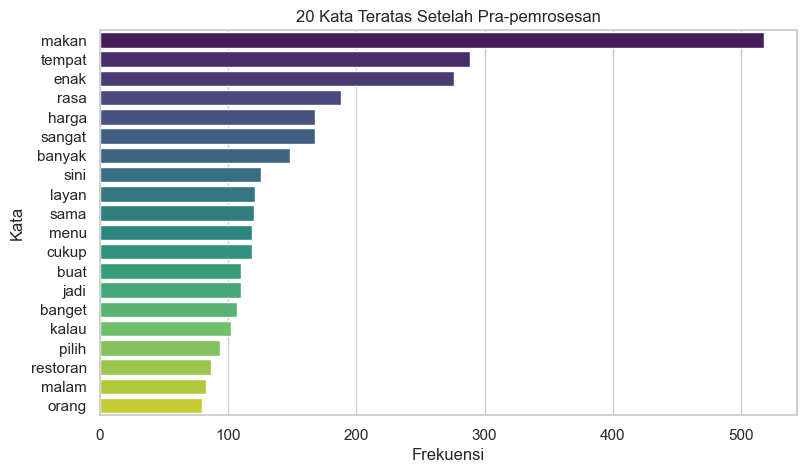

In [ ]:
# (c) Frekuensi kata-kata teratas (bar plot)
frekuensi = Counter([t for ts in df["tokens"] for t in ts])
top_kata = frekuensi.most_common(20)
df_top = pd.DataFrame(top_kata, columns=["kata", "frekuensi"])

ax = sns.barplot(data=df_top, x="frekuensi", y="kata", palette="viridis")
ax.set_title("20 Kata Teratas Setelah Pra-pemrosesan")
ax.set_xlabel("Frekuensi")
ax.set_ylabel("Kata")
plt.show()


## Bagian 5: Klasifikasi Teks (Poin 25)

### Rancangan Pemodelan
1. **Pisahkan data** menjadi set pelatihan (80%) dan set pengujian (20%) secara *stratified* (mempertahankan proporsi kelas).
2. **Ekstraksi fitur TF-IDF** — penting: `fit` hanya pada data latih, lalu `transform` data uji, agar tidak terjadi kebocoran informasi (*data leakage*).
3. **Latih** tiga classifier: **Multinomial Naive Bayes**, **Linear SVM**, dan **Logistic Regression**.
4. **Evaluasi** dengan metrik **accuracy, precision, recall, dan F1-score** pada data uji.


In [ ]:
from sklearn.model_selection import train_test_split

# Pisahkan data (stratified agar proporsi tiap kelas terjaga)
X_raw_train, X_raw_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"],
    test_size=0.20, random_state=42, stratify=df["label"]
)

print("Jumlah data latih:", len(X_raw_train))
print("Jumlah data uji  :", len(X_raw_test))
print("\nProporsi kelas latih:\n", y_train.map(NAMA_LABEL).value_counts(normalize=True).round(3))


Jumlah data latih: 800
Jumlah data uji  : 200

Proporsi kelas latih:
 label
negatif    0.382
positif    0.379
netral     0.239
Name: proportion, dtype: float64


In [ ]:
# Ekstraksi fitur TF-IDF: fit pada data LATIH saja, lalu transform keduanya
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train = tfidf.fit_transform(X_raw_train)
X_test = tfidf.transform(X_raw_test)

print("Dimensi X_train:", X_train.shape)
print("Dimensi X_test :", X_test.shape)


Dimensi X_train: (800, 5000)
Dimensi X_test : (200, 5000)


In [ ]:
# Latih dan evaluasi tiga classifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report)

model_model = {
    "Naive Bayes": MultinomialNB(),
    "SVM (Linear)": LinearSVC(max_iter=2000, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
}

hasil = []
for nama, model in model_model.items():
    model.fit(X_train, y_train)               # latih pada data latih
    prediksi = model.predict(X_test)          # prediksi pada data uji

    akurasi = accuracy_score(y_test, prediksi)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, prediksi, average="macro", zero_division=0
    )
    hasil.append({"Model": nama, "Accuracy": akurasi,
                  "Precision (macro)": precision, "Recall (macro)": recall,
                  "F1 (macro)": f1})

    print("=" * 60)
    print(f"Model: {nama}")
    print(classification_report(y_test, prediksi,
                                target_names=["negatif", "netral", "positif"]))


Model: Naive Bayes
              precision    recall  f1-score   support

     negatif       0.70      0.87      0.77        77
      netral       1.00      0.25      0.40        48
     positif       0.77      0.95      0.85        75

    accuracy                           0.75       200
   macro avg       0.82      0.69      0.67       200
weighted avg       0.80      0.75      0.71       200

Model: SVM (Linear)
              precision    recall  f1-score   support

     negatif       0.76      0.84      0.80        77
      netral       0.82      0.65      0.72        48
     positif       0.86      0.88      0.87        75

    accuracy                           0.81       200
   macro avg       0.81      0.79      0.80       200
weighted avg       0.81      0.81      0.81       200

Model: Logistic Regression
              precision    recall  f1-score   support

     negatif       0.74      0.86      0.80        77
      netral       0.84      0.56      0.68        48
     posi

In [ ]:
# Ringkasan perbandingan metrik
df_hasil = pd.DataFrame(hasil).round(3)
display(df_hasil)


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Naive Bayes,0.75,0.823,0.689,0.675
1,SVM (Linear),0.81,0.813,0.790,0.797
2,Logistic Regression,0.80,0.811,0.771,0.780


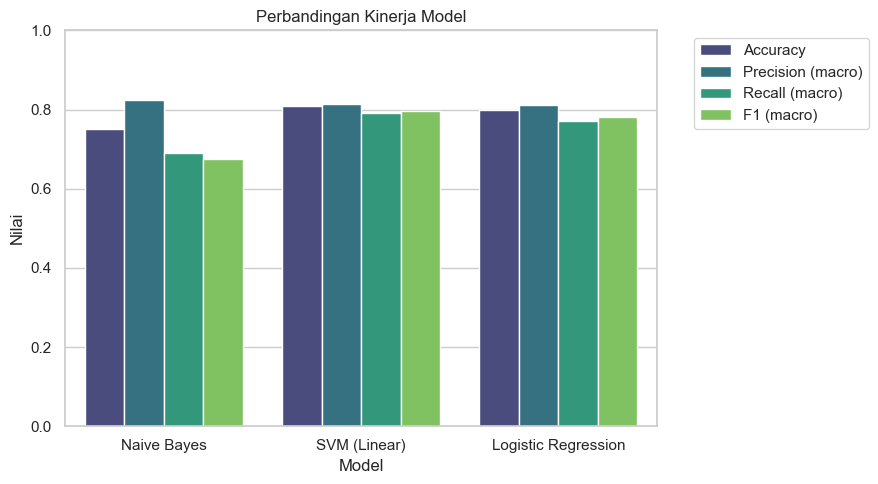

In [ ]:
# Visualisasi perbandingan metrik antar model
df_melt = df_hasil.melt(id_vars="Model", var_name="Metrik", value_name="Nilai")
ax = sns.barplot(data=df_melt, x="Model", y="Nilai", hue="Metrik", palette="viridis")
ax.set_ylim(0, 1)
ax.set_title("Perbandingan Kinerja Model")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


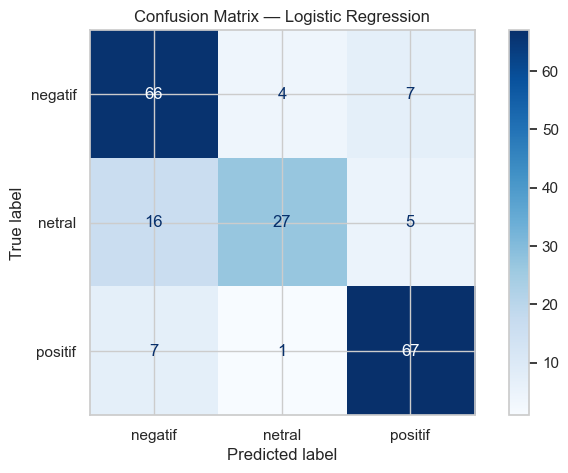

In [ ]:
# Confusion matrix model terbaik
from sklearn.metrics import ConfusionMatrixDisplay

model_terbaik = LogisticRegression(max_iter=2000, random_state=42)
model_terbaik.fit(X_train, y_train)

disp = ConfusionMatrixDisplay.from_estimator(
    model_terbaik, X_test, y_test,
    display_labels=["negatif", "netral", "positif"],
    cmap="Blues", values_format="d"
)
disp.ax_.set_title("Confusion Matrix — Logistic Regression")
plt.show()


## Bagian 6: Soal Teori (Poin 15)

### 6.1 Perbedaan *Text Classification* dan *Text Clustering*

| Aspek | Text Classification | Text Clustering |
|---|---|---|
| **Sifat pembelajaran** | *Supervised* (dengan label) | *Unsupervised* (tanpa label) |
| **Input** | Dokumen + label kelas yang telah ditentukan sebelumnya | Hanya dokumen (tanpa label) |
| **Output** | Setiap dokumen dipetakan ke **kategori yang sudah didefinisikan** | Dokumen **dikelompokkan** berdasarkan kemiripan; kelompok (klaster) terbentuk secara otomatis |
| **Tujuan** | Memprediksi label dokumen baru | Menemukan struktur/kelompok tersembunyi dalam data |
| **Contoh** | Deteksi spam, analisis sentimen, klasifikasi topik berita | Pengelompokan dokumen berita serupa, pemetaan topik riset |

Secara konseptual, **klasifikasi** adalah tugas *supervised*: model dilatih pada data berlabel lalu memprediksi label data baru. Sebaliknya, **clustering** adalah tugas *unsupervised* yang membagi data ke dalam kelompok-kelompok berdasarkan kemiripan tanpa mengetahui label sebelumnya (Manning et al., 2008; Sebastiani, 2002).

### 6.2 Kapan Text Clustering Dapat Dilakukan?

Text clustering bermanfaat pada situasi ketika **label data tidak tersedia** atau terlalu mahal untuk dibuat, dan kita ingin **menemukan struktur/kelompok yang belum diketahui** dari kumpulan teks. Contoh situasi dan kasusnya:

- **Pengelompokan hasil pencarian / berita** — mengelompokkan ribuan dokumen berita menjadi beberapa klaster topik yang saling terkait untuk mempermudah navigasi.
- **Analisis eksploratif topik** — memahami tema-tema dominan pada korpus besar (mis. komentar publik) sebelum menentukan skema label.
- **Deduplikasi dan deteksi dokumen serupa** — mengelompokkan dokumen yang hampir identik.
- **Segmentasi pelanggan dari ulasan** — mengelompokkan ulasan produk ke dalam tema keluhan/pujian yang belum ditentukan sebelumnya.

Intinya, clustering dipilih saat tujuannya **eksplorasi/penemuan kelompok**, bukan prediksi label yang telah ditentukan (Aggarwal & Zhai, 2012).

### 6.3 Menentukan Jumlah Klaster Optimal pada K-Means

Pada K-means, jumlah klaster `k` harus ditentukan terlebih dahulu. Dua metode umum untuk menentukannya:

1. **Metode Elbow (Elbow Method)**
   Jumlah klaster `k` dicoba pada suatu rentang nilai; untuk setiap `k` dihitung **Within-Cluster Sum of Squares (WCSS)** (total jarak kuadrat setiap titik ke pusat klasternya). Seiring bertambahnya `k`, WCSS menurun. Titik optimal dipilih pada **"siku" (elbow)** grafik, yaitu ketika penambahan `k` tidak lagi menurunkan WCSS secara signifikan (Thorndike, 1953).

2. **Metode Silhouette**
   Untuk setiap `k` dihitung **silhouette coefficient**, yang mengukur seberapa baik setiap objek berada dalam klasternya sendiri dibanding klaster lain (bernilai -1 hingga 1). Nilai **silhouette rata-rata tertinggi** menunjukkan jumlah klaster yang paling "rapat dan terpisah" (Rousseeuw, 1987).

### Referensi Pendukung (dengan posisi kalimat)

1. **Sebastiani, F. (2002).** *Machine Learning in Automated Text Categorization.* ACM Computing Surveys, 34(1), 1–47. — **Bagian 2 (Text Categorization)** mendefinisikan klasifikasi teks sebagai tugas *supervised*: *"Text categorization ... is the task of assigning a Boolean value to each pair ⟨d_j, c_i⟩ ∈ D × C, where D is a domain of documents and C = {c1, …, c|C|} is a set of predefined categories."*

2. **Manning, C. D., Raghavan, P., & Schütze, H. (2008).** *Introduction to Information Retrieval.* Cambridge University Press. — **Bab 13 bagian 13.1 (The text classification problem)** membahas klasifikasi *supervised* dengan kelas yang telah ditentukan; **Bab 16 bagian 16.1 (Clustering in information retrieval)** membahas *flat clustering* yang bekerja **tanpa** struktur/label yang ditentukan sebelumnya.

3. **Aggarwal, C. C., & Zhai, C. (2012).** *A Survey of Text Clustering Algorithms.* Dalam *Mining Text Data* (hal. 77–128). Springer. — **Bagian 1 (Introduction)** menjelaskan clustering sebagai metode *unsupervised* untuk menemukan kelompok; **Bagian 3.2 (K-means)** membahas algoritma K-means pada teks.

4. **Rousseeuw, P. J. (1987).** *Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis.* Journal of Computational and Applied Mathematics, 20, 53–65. — **Bagian 2 (Definition of silhouettes)** mendefinisikan silhouette *s(i)*; **Bagian 3 (Using silhouettes)** menunjukkan penggunaan silhouette (termasuk nilai rata-ratanya) untuk memilih jumlah klaster.

5. **Thorndike, R. L. (1953).** *Who Belongs in the Family?* Psychometrika, 18(4), 267–276. — Makalah klasik yang menjadi rujukan **metode elbow**: jumlah kelompok dipilih pada titik di mana penambahan kelompok tidak lagi menurunkan *within-group sum of squares* secara berarti.


## Kesimpulan

Notebook ini telah mendemonstrasikan solusi klasifikasi teks menyeluruh untuk isu **ujaran kebencian/hoaks di media sosial** (dengan studi kasus analisis sentimen sebagai tugas klasifikasi teks representatif):

1. **Data** — 1.000 kalimat sentimen Bahasa Indonesia dari NusaX-senti (positif/netral/negatif).
2. **Pra-pemrosesan** — lowercasing, penghapusan tanda baca, tokenisasi, penghapusan stopwords, dan stemming (Sastrawi).
3. **Fitur** — TF-IDF (sparse, per dokumen) dan Word2Vec (dense, per kata).
4. **Model** — Multinomial Naive Bayes, Linear SVM, dan Logistic Regression dengan evaluasi accuracy/precision/recall/F1.

Hasil eksperimen menunjukkan klasifikasi sentimen tiga kelas dapat dilakukan dengan akurasi yang baik menggunakan representasi TF-IDF dan classifier linear, sehingga pendekatan yang sama dapat diadaptasi untuk mendeteksi konten bermasalah (ujaran kebencian, hoaks) secara otomatis dan dalam skala besar.

### Referensi Dataset & Pustaka
- Winata, G. I., et al. (2022). *NusaX: Multilingual Parallel Sentiment Dataset for 10 Indonesian Local Languages.* arXiv:2205.15960. Dataset: `indonlp/NusaX-senti`.
- Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12, 2825–2830.
- Řehůřek, R., & Sojka, P. (2010). *Software Framework for Topic Modelling with Large Corpora.* LREC Workshop. (Gensim)
- Bird, S., Klein, E., & Loper, E. (2009). *Natural Language Processing with Python.* O'Reilly. (NLTK)
